## Simple Correspondence Analysis (SCA): `coverage` × 11 Variabel Lain
Dataset: `ibm_watson_coverage.csv` (9.134 baris, 12 kolom kategorikal).

Variabel **baris** selalu `coverage` (3 kategori), variabel **kolom** bergantian dengan 11 variabel lain.
Untuk setiap pasangan, perhitungan dilakukan berurutan seperti pada *Progres TA #7* dan dokumen perhitungan SCA:

1. Tabel kontingensi, uji χ², Cramér's V
2. Matriks korespondensi **P**, massa **r**, **c**, profil baris **R** dan profil kolom **C**
3. Matriks ekspektasi **E**, residual **P − E**, residual terstandarisasi **S**, total inersia
4. SVD lewat eigen-dekomposisi **SᵀS**, diverifikasi dengan `np.linalg.svd`, tabel inersia
5. Koordinat standar (Φ, Γ) dan utama (F, G), cek rumus transisi
6. Kontribusi, kualitas representasi (cos²), inersia titik
7. Peta simetris dan peta asimetris baris

> Catatan: ada **11 pasangan SCA**. Karena `coverage` hanya punya 3 kategori, dimensi maksimum tiap pasangan adalah min(I−1, J−1) = 2, jadi peta 2D menampung seluruh inersia.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, chi2_contingency
from IPython.display import display, Markdown

pd.set_option('display.float_format', lambda x: f'{x:.4f}')
pd.set_option('display.max_columns', 50)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

df = pd.read_csv('ibm_watson_coverage.csv')
print(df.shape, '| missing value:', int(df.isna().sum().sum()))
df.head()

(9134, 12) | missing value: 0


,coverage,education,employment_status,region,renew_offer_type,sales_channel,vehicle_class,income_cat,clv_cat,monthly_premium_cat,total_claim_cat,tenure_cat
0,Basic,Bachelor,Employed,Suburban,Offer1,Agent,Two-Door Car,Menengah,Q1 (Rendah),Q2 (Menengah),Q3 (Besar),Baru
1,Extended,Bachelor,Unemployed,Suburban,Offer3,Agent,Four-Door Car,Nol (0),Q3 (Tinggi),Q3 (Tinggi),Q4 (Sangat Besar),Menengah
2,Premium,Bachelor,Employed,Suburban,Offer1,Agent,Two-Door Car,Menengah,Q4 (Sangat Tinggi),Q3 (Tinggi),Q4 (Sangat Besar),Menengah
3,Basic,Bachelor,Unemployed,Suburban,Offer1,Call Center,SUV,Nol (0),Q3 (Tinggi),Q3 (Tinggi),Q3 (Besar),Lama
4,Basic,Bachelor,Employed,Rural,Offer1,Agent,Four-Door Car,Menengah,Q1 (Rendah),Q2 (Menengah),Q1 (Kecil),Menengah


In [2]:
ROW_VAR = 'coverage'
COL_VARS = [c for c in df.columns if c != ROW_VAR]
print(len(COL_VARS), 'pasangan:', COL_VARS)

# Urutan kategori agar tabel/peta mudah dibaca (variabel ordinal diurutkan menurut tingkatnya)
ORDER = {
    'coverage':   ['Basic', 'Extended', 'Premium'],
    'education':  ['High School or Below', 'College', 'Bachelor', 'Master', 'Doctor'],
    'income_cat': ['Nol (0)', 'Rendah', 'Menengah', 'Tinggi'],
    'tenure_cat': ['Baru', 'Menengah', 'Lama', 'Sangat Lama'],
}
def cats(var):
    present = set(df[var].unique())
    order = [c for c in ORDER.get(var, sorted(present)) if c in present]
    return order + sorted(present - set(order))

RESULTS = {}   # ringkasan tiap pasangan, diisi di akhir tiap bagian

11 pasangan: ['education', 'employment_status', 'region', 'renew_offer_type', 'sales_channel', 'vehicle_class', 'income_cat', 'clv_cat', 'monthly_premium_cat', 'total_claim_cat', 'tenure_cat']


In [3]:
# ================= Fungsi bantu (satu fungsi per langkah) =================
def langkah1_kontingensi(col):
    rows, cols = cats(ROW_VAR), cats(col)
    N = pd.crosstab(df[ROW_VAR], df[col]).reindex(index=rows, columns=cols)
    n = N.values.sum(); I, J = N.shape
    chi2_stat, p, dof, _ = chi2_contingency(N.values, correction=False)
    V = np.sqrt(chi2_stat / (n * min(I-1, J-1)))
    display(Markdown('**Tabel kontingensi N (dengan total)**'))
    display(N.assign(Total=N.sum(axis=1)).T.assign(Total=lambda t: t.sum(axis=1)).T.astype(int))
    print(f'I = {I}, J = {J}, n = {n}')
    print(f'chi2 = {chi2_stat:.4f}, db = {dof}, p-value = {p:.3e}, nilai kritis(0.05) = {chi2.ppf(0.95, dof):.4f}')
    print('Keputusan:', 'H0 ditolak -> ada hubungan signifikan' if p < 0.05 else 'H0 tidak ditolak -> tidak ada bukti hubungan')
    print(f"Cramer's V = {V:.4f}")
    return dict(col=col, N=N, n=n, I=I, J=J, chi2=chi2_stat, p=p, dof=dof, cramV=V,
                rl=list(N.index), cl=list(N.columns))

def langkah2_profil(st):
    N = st['N'].values.astype(float)
    P = N / st['n']
    r = P.sum(axis=1); c = P.sum(axis=0)
    Dr, Dc = np.diag(r), np.diag(c)
    R = np.linalg.inv(Dr) @ P          # profil baris
    C = np.linalg.inv(Dc) @ P.T        # profil kolom (baris C = kolom N)
    rl, cl = st['rl'], st['cl']
    display(Markdown('**P = N/n**')); display(pd.DataFrame(P, rl, cl))
    display(Markdown('**Massa baris r dan massa kolom c**'))
    display(pd.DataFrame({'r': r}, rl).T); display(pd.DataFrame({'c': c}, cl).T)
    display(Markdown('**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)')); display(pd.DataFrame(R, rl, cl))
    display(Markdown('**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)')); display(pd.DataFrame(C, cl, rl))
    st.update(P=P, r=r, c=c, Dr=Dr, Dc=Dc, R=R, C=C)

def langkah3_residual(st):
    P, r, c = st['P'], st['r'], st['c']
    E = np.outer(r, c); PE = P - E
    Dr_is = np.diag(1/np.sqrt(r)); Dc_is = np.diag(1/np.sqrt(c))
    S = Dr_is @ PE @ Dc_is
    rl, cl = st['rl'], st['cl']
    display(Markdown('**E = r cᵀ (ekspektasi di bawah independensi)**')); display(pd.DataFrame(E, rl, cl))
    display(Markdown('**P − E (residual mentah)**')); display(pd.DataFrame(PE, rl, cl))
    display(Markdown('**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**')); display(pd.DataFrame(S, rl, cl))
    tot = (S**2).sum()
    print(f'Total inersia = sum(S^2) = {tot:.6f}')
    print(f'Cek chi2/n   = {st["chi2"]/st["n"]:.6f}  (harus sama)')
    print(f'Cek baris/kolom P−E berjumlah 0: {np.allclose(PE.sum(1),0)} / {np.allclose(PE.sum(0),0)}')
    st.update(E=E, S=S, Dr_is=Dr_is, Dc_is=Dc_is, tot=tot)

def langkah4_svd(st):
    S, I, J = st['S'], st['I'], st['J']
    K = min(I-1, J-1)
    StS = S.T @ S
    eigval, eigvec = np.linalg.eigh(StS)
    o = np.argsort(eigval)[::-1]; eigval, eigvec = eigval[o], eigvec[:, o]
    lam = np.clip(eigval[:K], 0, None); sigma = np.sqrt(lam)
    V = eigvec[:, :K]
    # konvensi tanda: elemen terbesar (mutlak) tiap vektor dibuat positif
    for k in range(K):
        if V[np.argmax(np.abs(V[:, k])), k] < 0: V[:, k] *= -1
    U = S @ V @ np.diag(1/sigma)
    Sigma = np.diag(sigma)
    # verifikasi
    sv = np.linalg.svd(S, compute_uv=False)[:K]
    print(f'K = min(I-1, J-1) = {K}')
    print('Semua eigenvalue SᵀS (urut menurun):', np.round(eigval, 6), ' -> sisanya (≈0) dimensi trivial')
    print('Nilai singular (eigen)  :', np.round(sigma, 6))
    print('Nilai singular (np.svd) :', np.round(sv, 6), '| cocok:', np.allclose(sigma, sv))
    print('Galat maks |S - UΣVᵀ|   :', f'{np.abs(S - U @ Sigma @ V.T).max():.2e}')
    print('UᵀU = I:', np.allclose(U.T@U, np.eye(K)), '| VᵀV = I:', np.allclose(V.T@V, np.eye(K)))
    pct = lam / lam.sum() * 100
    tab = pd.DataFrame({'sigma_k': sigma, 'lambda_k': lam, '% inersia': pct, '% kumulatif': np.cumsum(pct)},
                       index=[f'Dim {k+1}' for k in range(K)])
    display(tab)
    print(f'Jumlah lambda = {lam.sum():.6f}  (total inersia = {st["tot"]:.6f})')
    st.update(K=K, lam=lam, sigma=sigma, Sigma=Sigma, U=U, V=V, pct=pct, inertia_table=tab)

def langkah5_koordinat(st):
    Dr_is, Dc_is, U, V, Sigma = st['Dr_is'], st['Dc_is'], st['U'], st['V'], st['Sigma']
    K = st['K']; dims = [f'Dim {k+1}' for k in range(K)]
    Phi = Dr_is @ U; Gamma = Dc_is @ V          # koordinat standar
    F = Phi @ Sigma; G = Gamma @ Sigma          # koordinat utama
    rl, cl = st['rl'], st['cl']
    for nama, M, idx in [('Φ  (standar baris)', Phi, rl), ('Γ  (standar kolom)', Gamma, cl),
                         ('F = ΦΣ  (utama baris)', F, rl), ('G = ΓΣ  (utama kolom)', G, cl)]:
        display(Markdown(f'**{nama}**')); display(pd.DataFrame(M, idx, dims))
    print('Cek ΦᵀDrΦ = I :', np.allclose(Phi.T @ st['Dr'] @ Phi, np.eye(K)),
          '| ΓᵀDcΓ = I :', np.allclose(Gamma.T @ st['Dc'] @ Gamma, np.eye(K)))
    print('Cek rumus transisi F = RΓ :', np.allclose(F, st['R'] @ Gamma),
          '| G = CΦ :', np.allclose(G, st['C'] @ Phi))
    st.update(Phi=Phi, Gamma=Gamma, F=F, G=G, dims=dims)

def _stats(mass, coord, lam, labels):
    sq = coord**2
    out = pd.DataFrame(index=labels)
    out['massa'] = mass
    for k in range(coord.shape[1]): out[f'ctr D{k+1} (%)'] = mass*sq[:, k]/lam[k]*100
    for k in range(coord.shape[1]): out[f'cos2 D{k+1}'] = sq[:, k]/sq.sum(1)
    out['inersia'] = mass*sq.sum(1)
    out['inersia (% total)'] = out['inersia']/mass.dot(sq.sum(1))*100
    return out

def langkah6_kontribusi(st):
    sr = _stats(st['r'], st['F'], st['lam'], st['rl'])
    sc = _stats(st['c'], st['G'], st['lam'], st['cl'])
    display(Markdown('**Baris (`coverage`)** | rata-rata kontribusi 1/I = %.1f%%' % (100/st['I']))); display(sr)
    display(Markdown('**Kolom (`%s`)** | rata-rata kontribusi 1/J = %.1f%%' % (st['col'], 100/st['J']))); display(sc)
    print(f'Jumlah inersia baris = {sr["inersia"].sum():.6f} | kolom = {sc["inersia"].sum():.6f} | total = {st["tot"]:.6f}')
    st.update(stats_row=sr, stats_col=sc)

def _label(ax, x, y, t, color, dx=4, dy=4):
    ax.annotate(t, (x, y), textcoords='offset points', xytext=(dx, dy), fontsize=9, color=color)

def langkah7_peta(st):
    F, G, Gam = st['F'], st['G'], st['Gamma']; pct = st['pct']; K = st['K']
    if K == 1:
        F = np.c_[F, np.zeros(len(F))]; G = np.c_[G, np.zeros(len(G))]; Gam = np.c_[Gam, np.zeros(len(Gam))]
        pct = np.r_[pct, 0.0]
    xl, yl = f'Dimensi 1 ({pct[0]:.2f}%)', f'Dimensi 2 ({pct[1]:.2f}%)'
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
    # --- peta simetris
    ax = axes[0]
    ax.scatter(F[:, 0], F[:, 1], c='tab:blue', s=60, label=f'baris ({ROW_VAR})')
    ax.scatter(G[:, 0], G[:, 1], c='tab:red', marker='^', s=60, label=f'kolom ({st["col"]})')
    for i, t in enumerate(st['rl']): _label(ax, F[i,0], F[i,1], t, 'tab:blue')
    for j, t in enumerate(st['cl']): _label(ax, G[j,0], G[j,1], t, 'tab:red')
    ax.axhline(0, c='k', lw=.6); ax.axvline(0, c='k', lw=.6)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title('Peta simetris (F dan G)'); ax.legend(loc='best', fontsize=8)
    ax.set_aspect('equal', adjustable='datalim')
    # --- peta asimetris baris
    ax = axes[1]
    ax.scatter(F[:, 0], F[:, 1], c='tab:blue', s=60, label=f'baris utama ({ROW_VAR})')
    ax.scatter(Gam[:, 0], Gam[:, 1], c='tab:red', marker='^', s=60, label=f'kolom standar ({st["col"]})')
    for i, t in enumerate(st['rl']): _label(ax, F[i,0], F[i,1], t, 'tab:blue')
    for j, t in enumerate(st['cl']): _label(ax, Gam[j,0], Gam[j,1], t, 'tab:red')
    ax.axhline(0, c='k', lw=.6); ax.axvline(0, c='k', lw=.6)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title('Peta asimetris baris (F dan Γ)'); ax.legend(loc='best', fontsize=8)
    fig.suptitle(f'SCA: {ROW_VAR} × {st["col"]}   (V = {st["cramV"]:.3f}, total inersia = {st["tot"]:.4f})', fontsize=12)
    plt.tight_layout(); plt.show()
    RESULTS[st['col']] = dict(I=st['I'], J=st['J'], chi2=st['chi2'], db=st['dof'], p_value=st['p'],
                              cramers_V=st['cramV'], total_inersia=st['tot'],
                              pct_dim1=st['pct'][0], pct_dim2=st['pct'][1] if len(st['pct']) > 1 else 0.0)

---
## 1. `coverage` × `education` (Pendidikan)

In [4]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'education'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

education,High School or Below,College,Bachelor,Master,Doctor,Total
coverage,,,,,,
Basic,1561,1628,1729,450,200,5568
Extended,800,827,769,224,122,2742
Premium,261,226,250,67,20,824
Total,2622,2681,2748,741,342,9134


I = 3, J = 5, n = 9134
chi2 = 18.6511, db = 8, p-value = 1.684e-02, nilai kritis(0.05) = 15.5073
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0320


In [5]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,High School or Below,College,Bachelor,Master,Doctor
Basic,0.1709,0.1782,0.1893,0.0493,0.0219
Extended,0.0876,0.0905,0.0842,0.0245,0.0134
Premium,0.0286,0.0247,0.0274,0.0073,0.0022


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,High School or Below,College,Bachelor,Master,Doctor
c,0.2871,0.2935,0.3009,0.0811,0.0374


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,High School or Below,College,Bachelor,Master,Doctor
Basic,0.2804,0.2924,0.3105,0.0808,0.0359
Extended,0.2918,0.3016,0.2805,0.0817,0.0445
Premium,0.3167,0.2743,0.3034,0.0813,0.0243


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
High School or Below,0.5953,0.3051,0.0995
College,0.6072,0.3085,0.0843
Bachelor,0.6292,0.2798,0.0910
Master,0.6073,0.3023,0.0904
Doctor,0.5848,0.3567,0.0585


In [6]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,High School or Below,College,Bachelor,Master,Doctor
Basic,0.1750,0.1789,0.1834,0.0495,0.0228
Extended,0.0862,0.0881,0.0903,0.0244,0.0112
Premium,0.0259,0.0265,0.0271,0.0073,0.0034


**P − E (residual mentah)**

,High School or Below,College,Bachelor,Master,Doctor
Basic,-0.0041,-0.0007,0.0059,-0.0002,-0.0009
Extended,0.0014,0.0024,-0.0061,0.0002,0.0021
Premium,0.0027,-0.0017,0.0002,0.0000,-0.0012


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,High School or Below,College,Bachelor,Master,Doctor
Basic,-0.0098,-0.0016,0.0138,-0.0008,-0.0061
Extended,0.0048,0.0082,-0.0204,0.0011,0.0200
Premium,0.0166,-0.0107,0.0014,0.0002,-0.0204


Total inersia = sum(S^2) = 0.002042
Cek chi2/n   = 0.002042  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [7]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 0.001423  0.000619  0.        0.       -0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.037721 0.024882]
Nilai singular (np.svd) : [0.037721 0.024882] | cocok: True
Galat maks |S - UΣVᵀ|   : 5.98e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0377,0.0014,69.6809,69.6809
Dim 2,0.0249,0.0006,30.3191,100.0000


Jumlah lambda = 0.002042  (total inersia = 0.002042)


In [8]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,-0.4152,-0.6842
Extended,1.3983,0.6131
Premium,-1.8476,2.5829


**Γ  (standar kolom)**

,Dim 1,Dim 2
High School or Below,-0.1181,1.4812
College,0.6222,-0.3456
Bachelor,-1.0077,-0.9612
Master,0.0930,0.1364
Doctor,3.9227,-1.2195


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,-0.0157,-0.0170
Extended,0.0527,0.0153
Premium,-0.0697,0.0643


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
High School or Below,-0.0045,0.0369
College,0.0235,-0.0086
Bachelor,-0.0380,-0.0239
Master,0.0035,0.0034
Doctor,0.1480,-0.0303


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [9]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,10.5079,28.5330,0.4584,0.5416,0.0003,15.9730
Extended,0.3002,58.6967,11.2836,0.9228,0.0772,0.0009,44.3215
Premium,0.0902,30.7954,60.1834,0.5404,0.4596,0.0008,39.7056


**Kolom (`education`)** | rata-rata kontribusi 1/J = 20.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
High School or Below,0.2871,0.4002,62.9813,0.0144,0.9856,0.0004,19.3742
College,0.2935,11.3642,3.5049,0.8817,0.1183,0.0002,8.9813
Bachelor,0.3009,30.5493,27.7950,0.7164,0.2836,0.0006,29.7142
Master,0.0811,0.0702,0.1509,0.5166,0.4834,0.0000,0.0946
Doctor,0.0374,57.6161,5.5679,0.9596,0.0404,0.0009,41.8356


Jumlah inersia baris = 0.002042 | kolom = 0.002042 | total = 0.002042


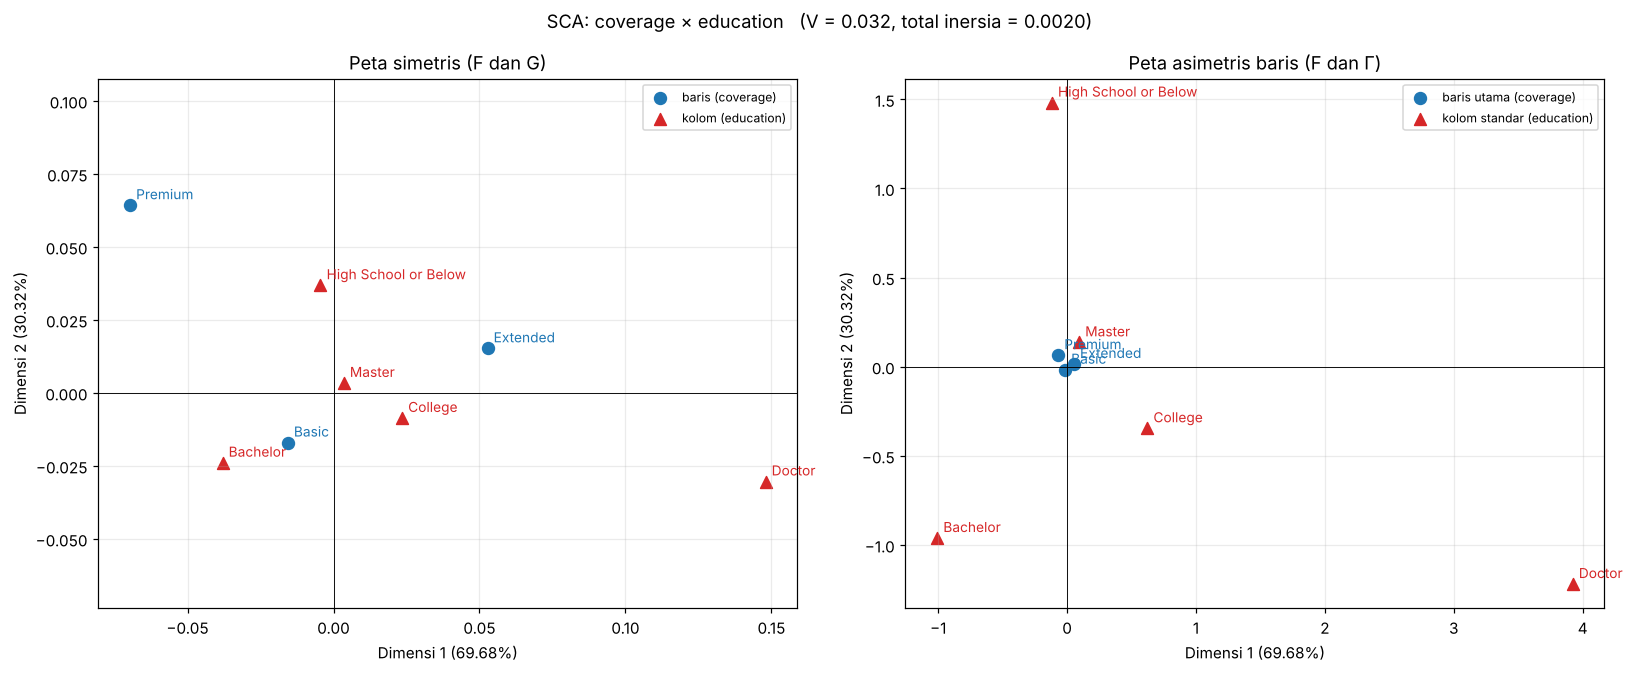

In [10]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 2. `coverage` × `employment_status` (Status pekerjaan)

In [11]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'employment_status'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

employment_status,Disabled,Employed,Medical Leave,Retired,Unemployed,Total
coverage,,,,,,
Basic,263,3471,274,170,1390,5568
Extended,96,1701,124,100,721,2742
Premium,46,526,34,12,206,824
Total,405,5698,432,282,2317,9134


I = 3, J = 5, n = 9134
chi2 = 21.7666, db = 8, p-value = 5.367e-03, nilai kritis(0.05) = 15.5073
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0345


In [12]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Disabled,Employed,Medical Leave,Retired,Unemployed
Basic,0.0288,0.3800,0.0300,0.0186,0.1522
Extended,0.0105,0.1862,0.0136,0.0109,0.0789
Premium,0.0050,0.0576,0.0037,0.0013,0.0226


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Disabled,Employed,Medical Leave,Retired,Unemployed
c,0.0443,0.6238,0.0473,0.0309,0.2537


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Disabled,Employed,Medical Leave,Retired,Unemployed
Basic,0.0472,0.6234,0.0492,0.0305,0.2496
Extended,0.0350,0.6204,0.0452,0.0365,0.2629
Premium,0.0558,0.6383,0.0413,0.0146,0.2500


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Disabled,0.6494,0.2370,0.1136
Employed,0.6092,0.2985,0.0923
Medical Leave,0.6343,0.2870,0.0787
Retired,0.6028,0.3546,0.0426
Unemployed,0.5999,0.3112,0.0889


In [13]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Disabled,Employed,Medical Leave,Retired,Unemployed
Basic,0.0270,0.3803,0.0288,0.0188,0.1546
Extended,0.0133,0.1873,0.0142,0.0093,0.0762
Premium,0.0040,0.0563,0.0043,0.0028,0.0229


**P − E (residual mentah)**

,Disabled,Employed,Medical Leave,Retired,Unemployed
Basic,0.0018,-0.0003,0.0012,-0.0002,-0.0025
Extended,-0.0028,-0.0010,-0.0006,0.0017,0.0028
Premium,0.0010,0.0013,-0.0005,-0.0015,-0.0003


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Disabled,Employed,Medical Leave,Retired,Unemployed
Basic,0.0107,-0.0004,0.0069,-0.0015,-0.0062
Extended,-0.0243,-0.0024,-0.0052,0.0174,0.0101
Premium,0.0164,0.0055,-0.0083,-0.0279,-0.0022


Total inersia = sum(S^2) = 0.002383
Cek chi2/n   = 0.002383  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [14]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 0.00205   0.000333  0.        0.       -0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.045278 0.018246]
Nilai singular (np.svd) : [0.045278 0.018246] | cocok: True
Galat maks |S - UΣVᵀ|   : 6.82e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0453,0.0021,86.0304,86.0304
Dim 2,0.0182,0.0003,13.9696,100.0000


Jumlah lambda = 0.002383  (total inersia = 0.002383)


In [15]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,-0.2657,0.7549
Extended,1.2424,-0.8874
Premium,-2.3391,-2.1479


**Γ  (standar kolom)**

,Dim 1,Dim 2
Disabled,-3.1738,1.9675
Employed,-0.1519,-0.1838
Medical Leave,0.0887,3.0156
Retired,3.9948,2.6846
Unemployed,0.4255,-0.7809


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,-0.0120,0.0138
Extended,0.0563,-0.0162
Premium,-0.1059,-0.0392


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Disabled,-0.1437,0.0359
Employed,-0.0069,-0.0034
Medical Leave,0.0040,0.0550
Retired,0.1809,0.0490
Unemployed,0.0193,-0.0142


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [16]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,4.3027,34.7383,0.4327,0.5673,0.0002,8.5544
Extended,0.3002,46.3382,23.6421,0.9235,0.0765,0.0010,43.1677
Premium,0.0902,49.3591,41.6196,0.8796,0.1204,0.0012,48.2780


**Kolom (`employment_status`)** | rata-rata kontribusi 1/J = 20.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Disabled,0.0443,44.6625,17.1637,0.9413,0.0587,0.0010,40.8210
Employed,0.6238,1.4387,2.1069,0.8079,0.1921,0.0000,1.5320
Medical Leave,0.0473,0.0372,43.0091,0.0053,0.9947,0.0001,6.0402
Retired,0.0309,49.2694,22.2501,0.9317,0.0683,0.0011,45.4949
Unemployed,0.2537,4.5922,15.4701,0.6464,0.3536,0.0001,6.1118


Jumlah inersia baris = 0.002383 | kolom = 0.002383 | total = 0.002383


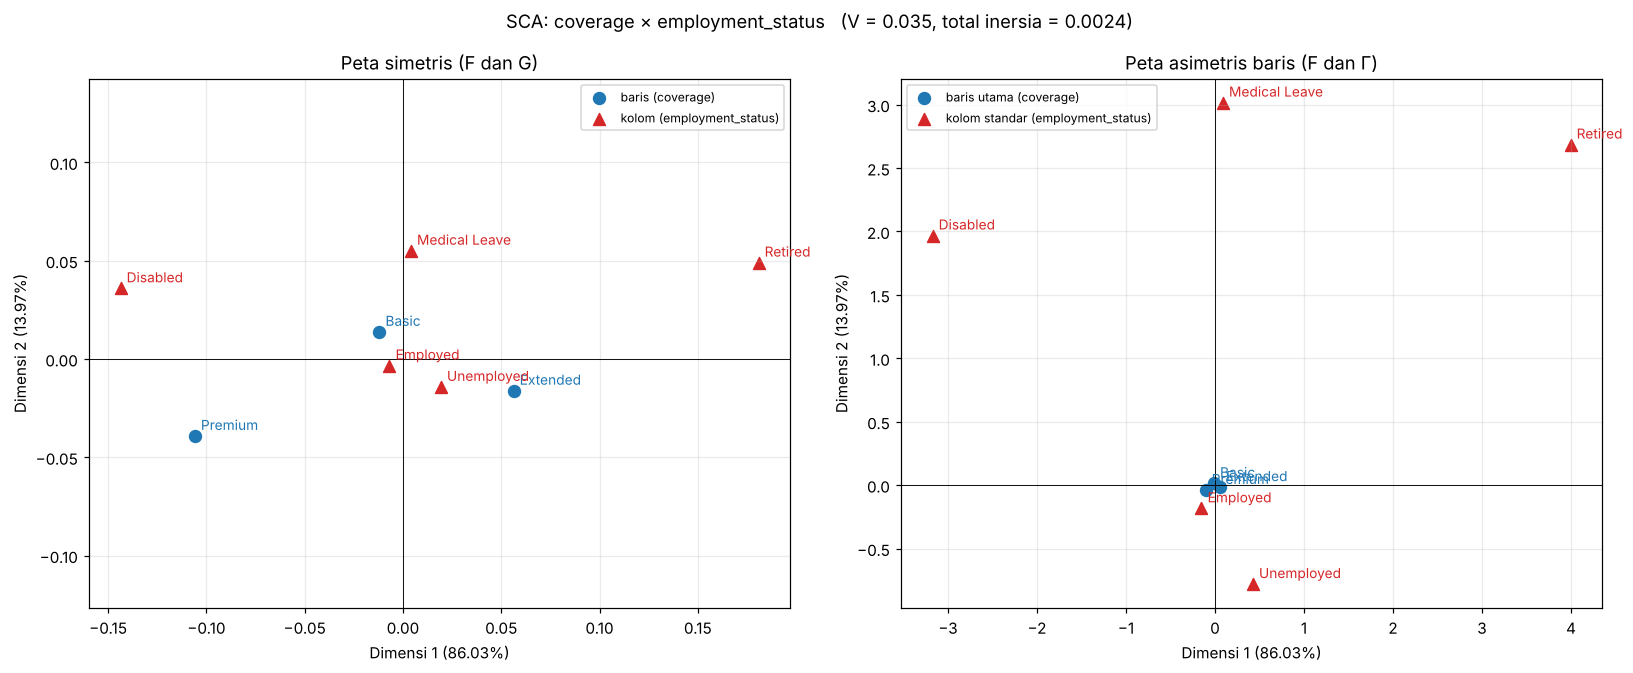

In [17]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 3. `coverage` × `region` (Wilayah)

In [18]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'region'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

region,Rural,Suburban,Urban,Total
coverage,,,,
Basic,1100,3448,1020,5568
Extended,526,1747,469,2742
Premium,147,584,93,824
Total,1773,5779,1582,9134


I = 3, J = 3, n = 9134
chi2 = 31.2698, db = 4, p-value = 2.697e-06, nilai kritis(0.05) = 9.4877
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0414


In [19]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Rural,Suburban,Urban
Basic,0.1204,0.3775,0.1117
Extended,0.0576,0.1913,0.0513
Premium,0.0161,0.0639,0.0102


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Rural,Suburban,Urban
c,0.1941,0.6327,0.1732


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Rural,Suburban,Urban
Basic,0.1976,0.6193,0.1832
Extended,0.1918,0.6371,0.1710
Premium,0.1784,0.7087,0.1129


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Rural,0.6204,0.2967,0.0829
Suburban,0.5966,0.3023,0.1011
Urban,0.6448,0.2965,0.0588


In [20]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Rural,Suburban,Urban
Basic,0.1183,0.3857,0.1056
Extended,0.0583,0.1899,0.0520
Premium,0.0175,0.0571,0.0156


**P − E (residual mentah)**

,Rural,Suburban,Urban
Basic,0.0021,-0.0082,0.0061
Extended,-0.0007,0.0013,-0.0006
Premium,-0.0014,0.0069,-0.0054


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Rural,Suburban,Urban
Basic,0.0061,-0.0132,0.0187
Extended,-0.0028,0.0031,-0.0028
Premium,-0.0107,0.0287,-0.0435


Total inersia = sum(S^2) = 0.003423
Cek chi2/n   = 0.003423  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [21]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 3.417e-03  7.000e-06 -0.000e+00]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.058454 0.002562]
Nilai singular (np.svd) : [0.058454 0.002562] | cocok: True
Galat maks |S - UΣVᵀ|   : 5.90e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0585,0.0034,99.8082,99.8082
Dim 2,0.0026,0.0000,0.1918,100.0000


Jumlah lambda = 0.003423  (total inersia = 0.003423)


In [22]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,0.5190,0.6091
Extended,-0.1426,-1.5201
Premium,-3.0326,0.9424


**Γ  (standar kolom)**

,Dim 1,Dim 2
Rural,0.4836,1.9794
Suburban,-0.6826,-0.3384
Urban,1.9517,-0.9820


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,0.0303,0.0016
Extended,-0.0083,-0.0039
Premium,-0.1773,0.0024


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Rural,0.0283,0.0051
Suburban,-0.0399,-0.0009
Urban,0.1141,-0.0025


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [23]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,16.4223,22.6186,0.9974,0.0026,0.0006,16.4342
Extended,0.3002,0.6108,69.3695,0.8209,0.1791,0.0000,0.7426
Premium,0.0902,82.9669,8.0119,0.9998,0.0002,0.0028,82.8232


**Kolom (`region`)** | rata-rata kontribusi 1/J = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Rural,0.1941,4.5391,76.0499,0.9688,0.0312,0.0002,4.6762
Suburban,0.6327,29.4841,7.2468,0.9995,0.0005,0.0010,29.4414
Urban,0.1732,65.9768,16.7033,0.9995,0.0005,0.0023,65.8823


Jumlah inersia baris = 0.003423 | kolom = 0.003423 | total = 0.003423


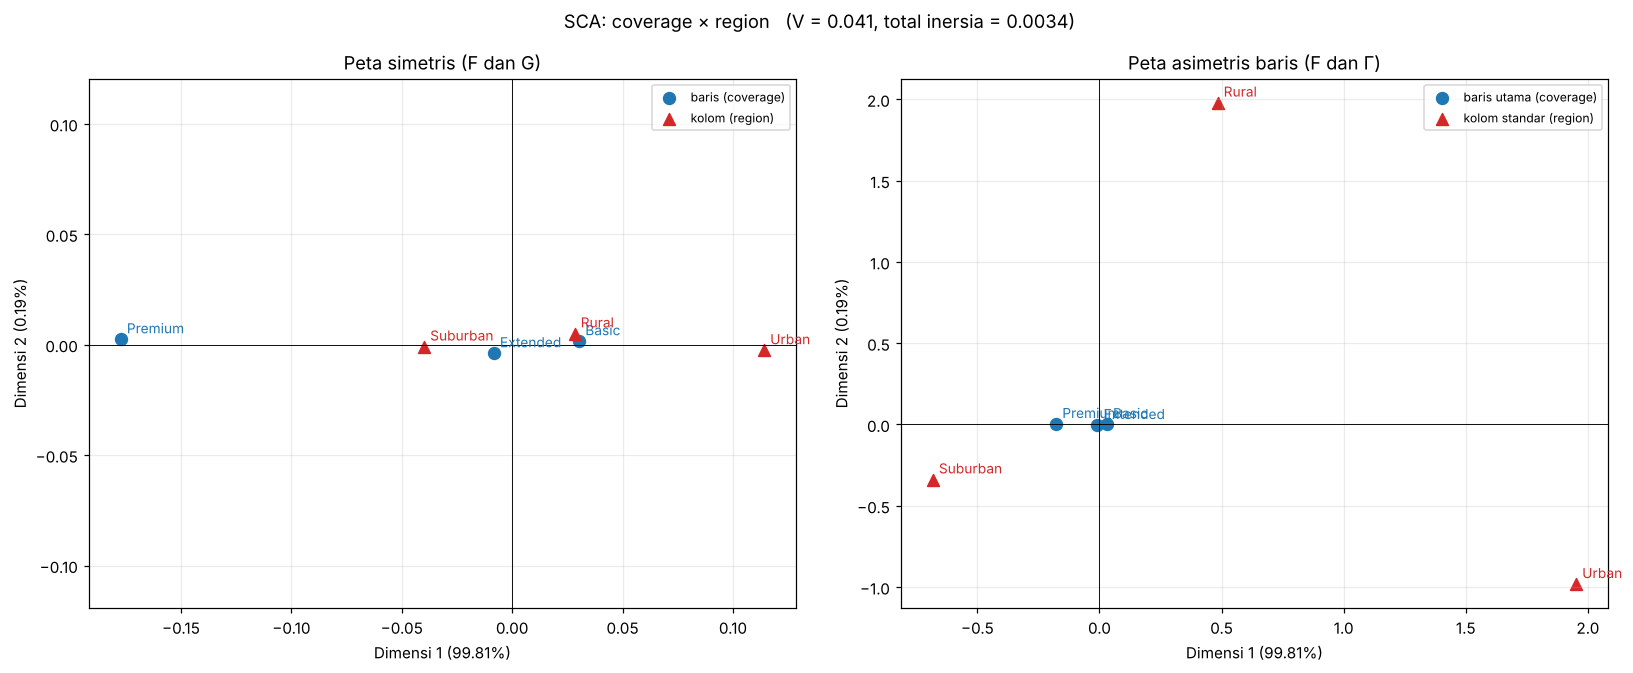

In [24]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 4. `coverage` × `renew_offer_type` (Tipe penawaran perpanjangan)

In [25]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'renew_offer_type'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

renew_offer_type,Offer1,Offer2,Offer3,Offer4,Total
coverage,,,,,
Basic,2202,1831,887,648,5568
Extended,1128,877,425,312,2742
Premium,422,218,120,64,824
Total,3752,2926,1432,1024,9134


I = 3, J = 4, n = 9134
chi2 = 43.6737, db = 6, p-value = 8.579e-08, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0489


In [26]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Offer1,Offer2,Offer3,Offer4
Basic,0.2411,0.2005,0.0971,0.0709
Extended,0.1235,0.0960,0.0465,0.0342
Premium,0.0462,0.0239,0.0131,0.0070


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Offer1,Offer2,Offer3,Offer4
c,0.4108,0.3203,0.1568,0.1121


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Offer1,Offer2,Offer3,Offer4
Basic,0.3955,0.3288,0.1593,0.1164
Extended,0.4114,0.3198,0.1550,0.1138
Premium,0.5121,0.2646,0.1456,0.0777


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Offer1,0.5869,0.3006,0.1125
Offer2,0.6258,0.2997,0.0745
Offer3,0.6194,0.2968,0.0838
Offer4,0.6328,0.3047,0.0625


In [27]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Offer1,Offer2,Offer3,Offer4
Basic,0.2504,0.1953,0.0956,0.0683
Extended,0.1233,0.0962,0.0471,0.0337
Premium,0.0371,0.0289,0.0141,0.0101


**P − E (residual mentah)**

,Offer1,Offer2,Offer3,Offer4
Basic,-0.0093,0.0052,0.0015,0.0026
Extended,0.0002,-0.0002,-0.0005,0.0005
Premium,0.0091,-0.0050,-0.0010,-0.0031


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Offer1,Offer2,Offer3,Offer4
Basic,-0.0186,0.0117,0.0050,0.0100
Extended,0.0005,-0.0005,-0.0025,0.0027
Premium,0.0475,-0.0296,-0.0085,-0.0309


Total inersia = sum(S^2) = 0.004781
Cek chi2/n   = 0.004781  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [28]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 4.761e-03  2.000e-05  0.000e+00 -0.000e+00]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.069003 0.004471]
Nilai singular (np.svd) : [0.069003 0.004471] | cocok: True
Galat maks |S - UΣVᵀ|   : 3.61e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0690,0.0048,99.5819,99.5819
Dim 2,0.0045,0.0000,0.4181,100.0000


Jumlah lambda = 0.004781  (total inersia = 0.004781)


In [29]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,-0.4560,-0.6576
Extended,-0.0089,1.5268
Premium,3.1112,-0.6368


**Γ  (standar kolom)**

,Dim 1,Dim 2
Offer1,1.1537,0.3201
Offer2,-0.8151,-0.3031
Offer3,-0.3536,-1.6955
Offer4,-1.4035,2.0644


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,-0.0315,-0.0029
Extended,-0.0006,0.0068
Premium,0.2147,-0.0028


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Offer1,0.0796,0.0014
Offer2,-0.0562,-0.0014
Offer3,-0.0244,-0.0076
Offer4,-0.0968,0.0092


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [30]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,12.6768,26.3641,0.9913,0.0087,0.0006,12.7341
Extended,0.3002,0.0024,69.9779,0.0081,0.9919,0.0000,0.2950
Premium,0.0902,87.3208,3.6580,0.9998,0.0002,0.0042,86.9709


**Kolom (`renew_offer_type`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Offer1,0.4108,54.6724,4.2082,0.9997,0.0003,0.0026,54.4614
Offer2,0.3203,21.2826,2.9434,0.9994,0.0006,0.0010,21.2059
Offer3,0.1568,1.9607,45.0689,0.9120,0.0880,0.0001,2.1410
Offer4,0.1121,22.0843,47.7794,0.9910,0.0090,0.0011,22.1917


Jumlah inersia baris = 0.004781 | kolom = 0.004781 | total = 0.004781


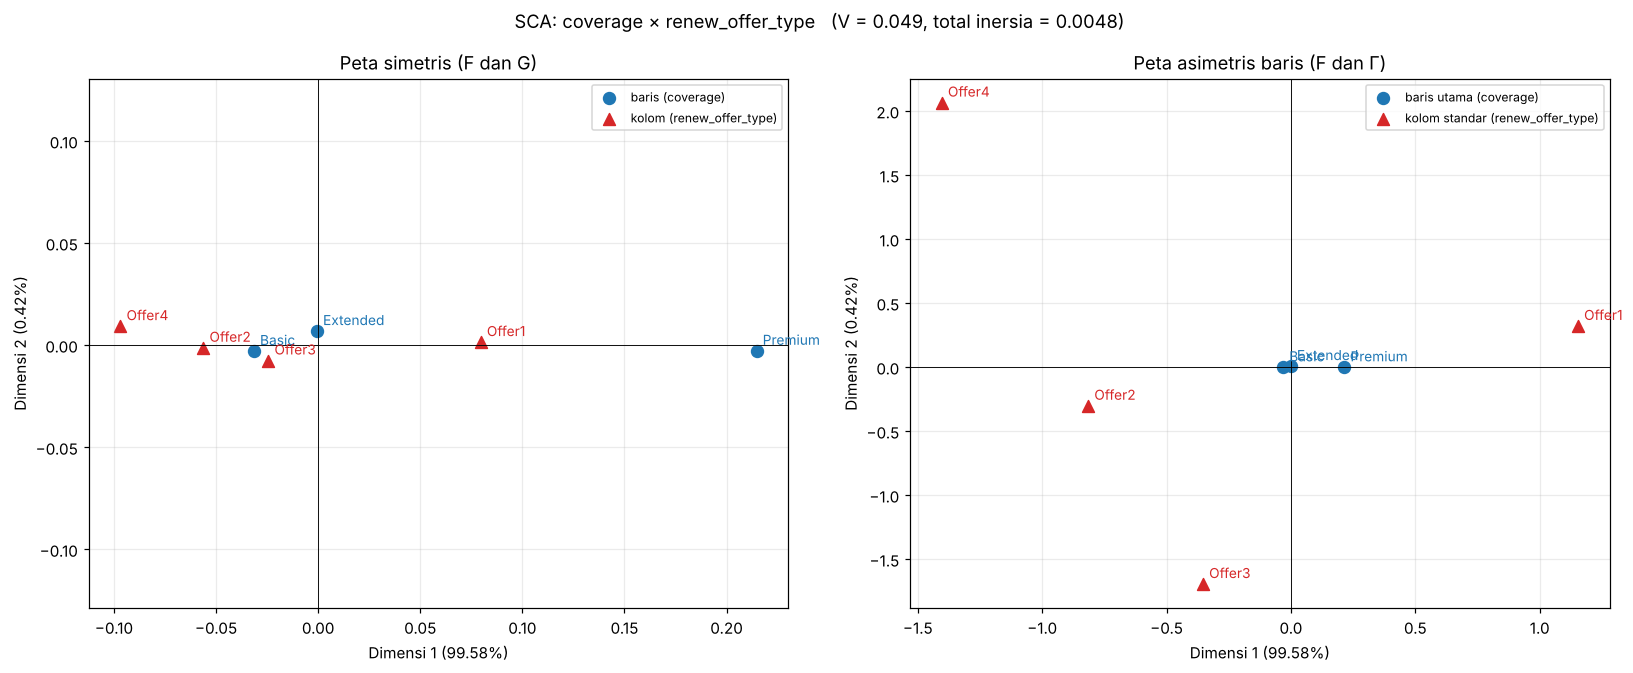

In [31]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 5. `coverage` × `sales_channel` (Kanal penjualan)

In [32]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'sales_channel'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

sales_channel,Agent,Branch,Call Center,Web,Total
coverage,,,,,
Basic,2069,1544,1104,851,5568
Extended,1099,785,508,350,2742
Premium,309,238,153,124,824
Total,3477,2567,1765,1325,9134


I = 3, J = 4, n = 9134
chi2 = 15.0189, db = 6, p-value = 2.011e-02, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0287


In [33]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Agent,Branch,Call Center,Web
Basic,0.2265,0.1690,0.1209,0.0932
Extended,0.1203,0.0859,0.0556,0.0383
Premium,0.0338,0.0261,0.0168,0.0136


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Agent,Branch,Call Center,Web
c,0.3807,0.2810,0.1932,0.1451


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Agent,Branch,Call Center,Web
Basic,0.3716,0.2773,0.1983,0.1528
Extended,0.4008,0.2863,0.1853,0.1276
Premium,0.3750,0.2888,0.1857,0.1505


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Agent,0.5951,0.3161,0.0889
Branch,0.6015,0.3058,0.0927
Call Center,0.6255,0.2878,0.0867
Web,0.6423,0.2642,0.0936


In [34]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Agent,Branch,Call Center,Web
Basic,0.2321,0.1713,0.1178,0.0884
Extended,0.1143,0.0844,0.0580,0.0435
Premium,0.0343,0.0254,0.0174,0.0131


**P − E (residual mentah)**

,Agent,Branch,Call Center,Web
Basic,-0.0055,-0.0023,0.0031,0.0047
Extended,0.0060,0.0016,-0.0024,-0.0052
Premium,-0.0005,0.0007,-0.0007,0.0005


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Agent,Branch,Call Center,Web
Basic,-0.0115,-0.0055,0.0090,0.0159
Extended,0.0179,0.0054,-0.0099,-0.0251
Premium,-0.0028,0.0044,-0.0052,0.0043


Total inersia = sum(S^2) = 0.001644
Cek chi2/n   = 0.001644  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [35]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 1.57e-03  7.40e-05  0.00e+00 -0.00e+00]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.039626 0.008607]
Nilai singular (np.svd) : [0.039626 0.008607] | cocok: True
Galat maks |S - UΣVᵀ|   : 2.78e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0396,0.0016,95.4947,95.4947
Dim 2,0.0086,0.0001,4.5053,100.0000


Jumlah lambda = 0.001644  (total inersia = 0.001644)


In [36]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,0.7160,0.3574
Extended,-1.5098,0.2270
Premium,0.1858,-3.1702


**Γ  (standar kolom)**

,Dim 1,Dim 2
Agent,-0.8741,0.3097
Branch,-0.3485,-1.1108
Call Center,0.7425,1.6331
Web,1.9797,-0.8360


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,0.0284,0.0031
Extended,-0.0598,0.0020
Premium,0.0074,-0.0273


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Agent,-0.0346,0.0027
Branch,-0.0138,-0.0096
Call Center,0.0294,0.0141
Web,0.0784,-0.0072


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [37]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,31.2547,7.7863,0.9884,0.0116,0.0005,30.1973
Extended,0.3002,68.4340,1.5463,0.9989,0.0011,0.0011,65.4205
Premium,0.0902,0.3113,90.6674,0.0678,0.9322,0.0001,4.3821


**Kolom (`sales_channel`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Agent,0.3807,29.0818,3.6500,0.9941,0.0059,0.0005,27.9360
Branch,0.2810,3.4128,34.6761,0.6760,0.3240,0.0001,4.8213
Call Center,0.1932,10.6537,51.5360,0.8142,0.1858,0.0002,12.4956
Web,0.1451,56.8517,10.1380,0.9917,0.0083,0.0009,54.7471


Jumlah inersia baris = 0.001644 | kolom = 0.001644 | total = 0.001644


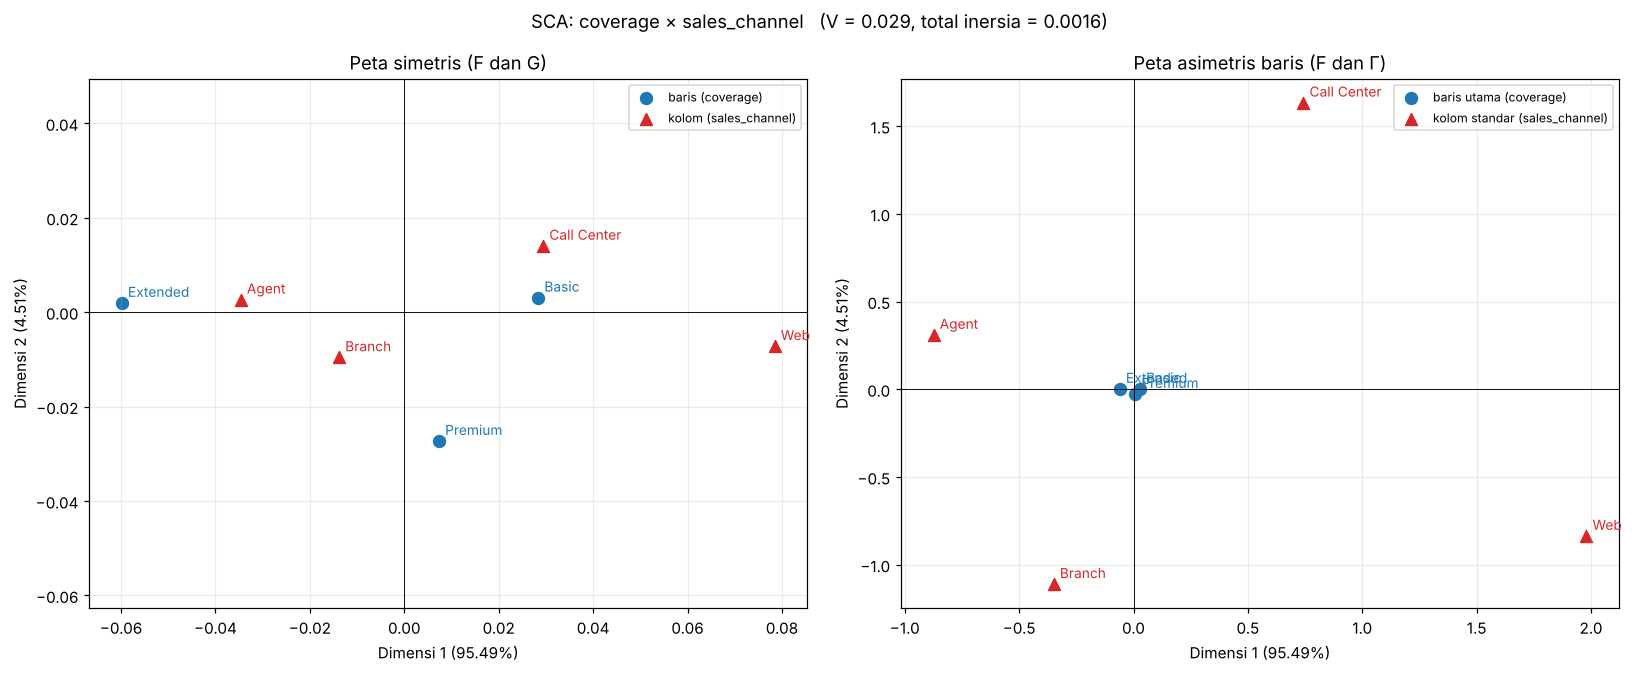

In [38]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 6. `coverage` × `vehicle_class` (Kelas kendaraan)

In [39]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'vehicle_class'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

vehicle_class,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car,Total
coverage,,,,,,,
Basic,2795,92,94,1117,292,1178,5568
Extended,1403,49,64,529,145,552,2742
Premium,423,22,26,150,47,156,824
Total,4621,163,184,1796,484,1886,9134


I = 3, J = 6, n = 9134
chi2 = 18.3085, db = 10, p-value = 4.998e-02, nilai kritis(0.05) = 18.3070
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0317


In [40]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car
Basic,0.3060,0.0101,0.0103,0.1223,0.0320,0.1290
Extended,0.1536,0.0054,0.0070,0.0579,0.0159,0.0604
Premium,0.0463,0.0024,0.0028,0.0164,0.0051,0.0171


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car
c,0.5059,0.0178,0.0201,0.1966,0.0530,0.2065


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car
Basic,0.5020,0.0165,0.0169,0.2006,0.0524,0.2116
Extended,0.5117,0.0179,0.0233,0.1929,0.0529,0.2013
Premium,0.5133,0.0267,0.0316,0.1820,0.0570,0.1893


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Four-Door Car,0.6048,0.3036,0.0915
Luxury Car,0.5644,0.3006,0.1350
Luxury SUV,0.5109,0.3478,0.1413
SUV,0.6219,0.2945,0.0835
Sports Car,0.6033,0.2996,0.0971
Two-Door Car,0.6246,0.2927,0.0827


In [41]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car
Basic,0.3084,0.0109,0.0123,0.1199,0.0323,0.1259
Extended,0.1519,0.0054,0.0060,0.0590,0.0159,0.0620
Premium,0.0456,0.0016,0.0018,0.0177,0.0048,0.0186


**P − E (residual mentah)**

,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car
Basic,-0.0024,-0.0008,-0.0020,0.0024,-0.0003,0.0031
Extended,0.0017,0.0000,0.0010,-0.0011,-0.0000,-0.0016
Premium,0.0007,0.0008,0.0010,-0.0013,0.0004,-0.0015


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Four-Door Car,Luxury Car,Luxury SUV,SUV,Sports Car,Two-Door Car
Basic,-0.0043,-0.0077,-0.0179,0.0070,-0.0019,0.0087
Extended,0.0044,0.0001,0.0123,-0.0046,-0.0003,-0.0062
Premium,0.0031,0.0199,0.0241,-0.0099,0.0053,-0.0113


Total inersia = sum(S^2) = 0.002004
Cek chi2/n   = 0.002004  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [42]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 1.915e-03  9.000e-05  0.000e+00  0.000e+00 -0.000e+00 -0.000e+00]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.043758 0.009467]
Nilai singular (np.svd) : [0.043758 0.009467] | cocok: True
Galat maks |S - UΣVᵀ|   : 2.69e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0438,0.0019,95.5286,95.5286
Dim 2,0.0095,0.0001,4.4714,100.0000


Jumlah lambda = 0.002004  (total inersia = 0.002004)


In [43]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,-0.6666,0.4428
Extended,0.5554,-1.4222
Premium,2.6562,1.7405


**Γ  (standar kolom)**

,Dim 1,Dim 2
Four-Door Car,0.1961,-0.4913
Luxury Car,3.4103,6.0530
Luxury SUV,5.2099,-2.3793
SUV,-0.6662,0.1962
Sports Car,0.5065,1.0654
Two-Door Car,-0.7792,0.4525


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,-0.0292,0.0042
Extended,0.0243,-0.0135
Premium,0.1162,0.0165


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Four-Door Car,0.0086,-0.0047
Luxury Car,0.1492,0.0573
Luxury SUV,0.2280,-0.0225
SUV,-0.0292,0.0019
Sports Car,0.0222,0.0101
Two-Door Car,-0.0341,0.0043


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [44]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,27.0888,11.9522,0.9798,0.0202,0.0005,26.4120
Extended,0.3002,9.2610,60.7193,0.7652,0.2348,0.0002,11.5619
Premium,0.0902,63.6502,27.3286,0.9803,0.0197,0.0012,62.0261


**Kolom (`vehicle_class`)** | rata-rata kontribusi 1/J = 16.7%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Four-Door Car,0.5059,1.9461,12.2124,0.7730,0.2270,0.0000,2.4052
Luxury Car,0.0178,20.7545,65.3839,0.8715,0.1285,0.0005,22.7501
Luxury SUV,0.0201,54.6776,11.4042,0.9903,0.0097,0.0011,52.7427
SUV,0.1966,8.7259,0.7572,0.9960,0.0040,0.0002,8.3696
Sports Car,0.0530,1.3596,6.0142,0.8285,0.1715,0.0000,1.5677
Two-Door Car,0.2065,12.5363,4.2282,0.9845,0.0155,0.0002,12.1648


Jumlah inersia baris = 0.002004 | kolom = 0.002004 | total = 0.002004


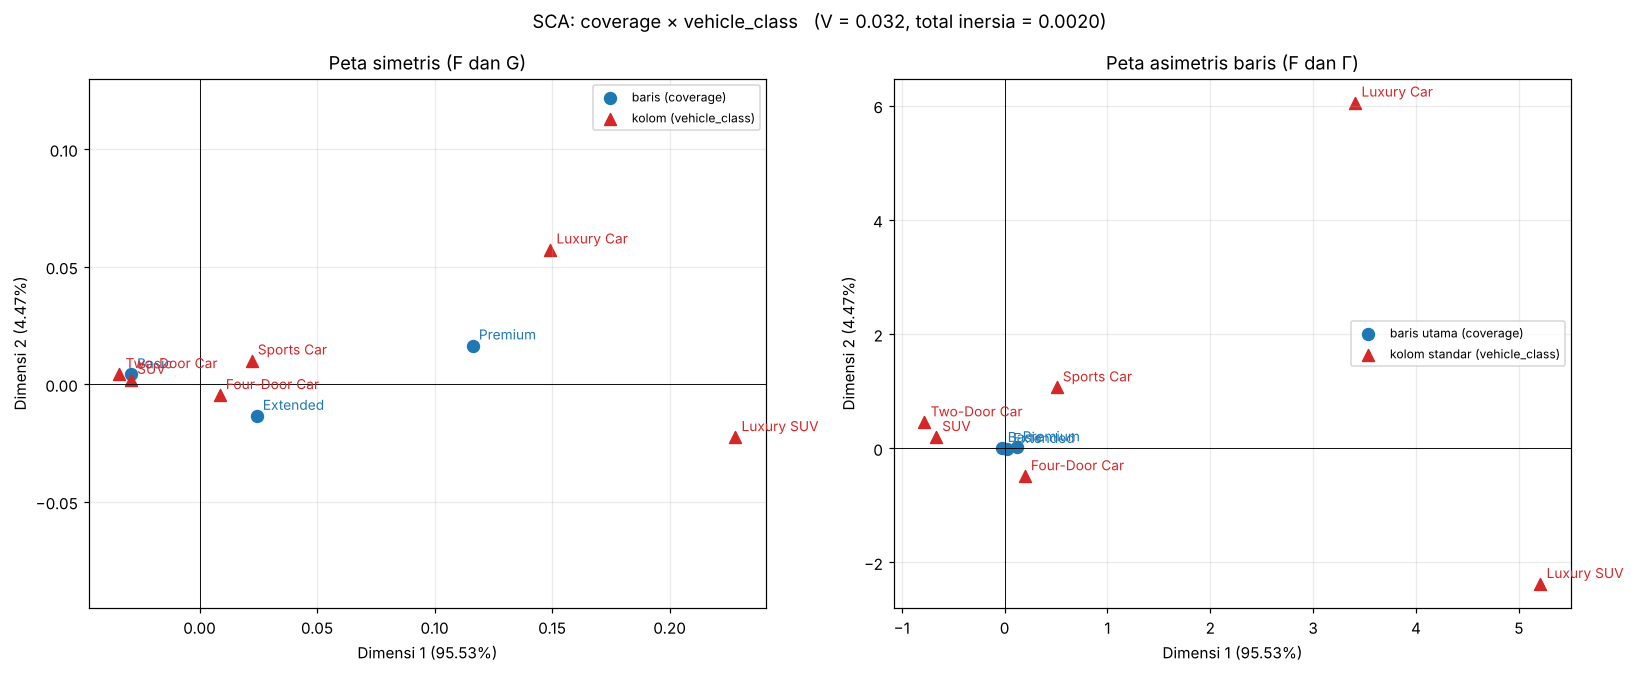

In [45]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 7. `coverage` × `income_cat` (Kategori pendapatan)

In [46]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'income_cat'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

income_cat,Nol (0),Rendah,Menengah,Tinggi,Total
coverage,,,,,
Basic,1390,1402,1332,1444,5568
Extended,721,686,716,619,2742
Premium,206,185,224,209,824
Total,2317,2273,2272,2272,9134


I = 3, J = 4, n = 9134
chi2 = 17.4127, db = 6, p-value = 7.881e-03, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0309


In [47]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Nol (0),Rendah,Menengah,Tinggi
Basic,0.1522,0.1535,0.1458,0.1581
Extended,0.0789,0.0751,0.0784,0.0678
Premium,0.0226,0.0203,0.0245,0.0229


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Nol (0),Rendah,Menengah,Tinggi
c,0.2537,0.2489,0.2487,0.2487


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Nol (0),Rendah,Menengah,Tinggi
Basic,0.2496,0.2518,0.2392,0.2593
Extended,0.2629,0.2502,0.2611,0.2257
Premium,0.2500,0.2245,0.2718,0.2536


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Nol (0),0.5999,0.3112,0.0889
Rendah,0.6168,0.3018,0.0814
Menengah,0.5863,0.3151,0.0986
Tinggi,0.6356,0.2724,0.0920


In [48]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Nol (0),Rendah,Menengah,Tinggi
Basic,0.1546,0.1517,0.1516,0.1516
Extended,0.0762,0.0747,0.0747,0.0747
Premium,0.0229,0.0224,0.0224,0.0224


**P − E (residual mentah)**

,Nol (0),Rendah,Menengah,Tinggi
Basic,-0.0025,0.0018,-0.0058,0.0065
Extended,0.0028,0.0004,0.0037,-0.0069
Premium,-0.0003,-0.0022,0.0021,0.0004


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Nol (0),Rendah,Menengah,Tinggi
Basic,-0.0062,0.0046,-0.0149,0.0166
Extended,0.0101,0.0015,0.0136,-0.0253
Premium,-0.0022,-0.0147,0.0139,0.0030


Total inersia = sum(S^2) = 0.001906
Cek chi2/n   = 0.001906  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [49]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [0.001478 0.000428 0.       0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.038444 0.020698]
Nilai singular (np.svd) : [0.038444 0.020698] | cocok: True
Galat maks |S - UΣVᵀ|   : 7.11e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0384,0.0015,77.5273,77.5273
Dim 2,0.0207,0.0004,22.4727,100.0000


Jumlah lambda = 0.001906  (total inersia = 0.001906)


In [50]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,0.7809,0.1749
Extended,-1.4111,0.5831
Premium,-0.5815,-3.1220


**Γ  (standar kolom)**

,Dim 1,Dim 2
Nol (0),-0.5799,0.4244
Rendah,0.2210,1.4369
Menengah,-1.1490,-1.0399
Tinggi,1.5193,-0.8304


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,0.0300,0.0036
Extended,-0.0542,0.0121
Premium,-0.0224,-0.0646


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Nol (0),-0.0223,0.0088
Rendah,0.0085,0.0297
Menengah,-0.0442,-0.0215
Tinggi,0.0584,-0.0172


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [51]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,37.1772,1.8638,0.9857,0.0143,0.0006,29.2413
Extended,0.3002,59.7725,10.2078,0.9528,0.0472,0.0009,48.6340
Premium,0.0902,3.0503,87.9284,0.1069,0.8931,0.0004,22.1247


**Kolom (`income_cat`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Nol (0),0.2537,8.5305,4.5681,0.8656,0.1344,0.0001,7.6401
Rendah,0.2489,1.2158,51.3806,0.0755,0.9245,0.0002,12.4892
Menengah,0.2487,32.8398,26.8980,0.8081,0.1919,0.0006,31.5045
Tinggi,0.2487,57.4139,17.1533,0.9203,0.0797,0.0009,48.3662


Jumlah inersia baris = 0.001906 | kolom = 0.001906 | total = 0.001906


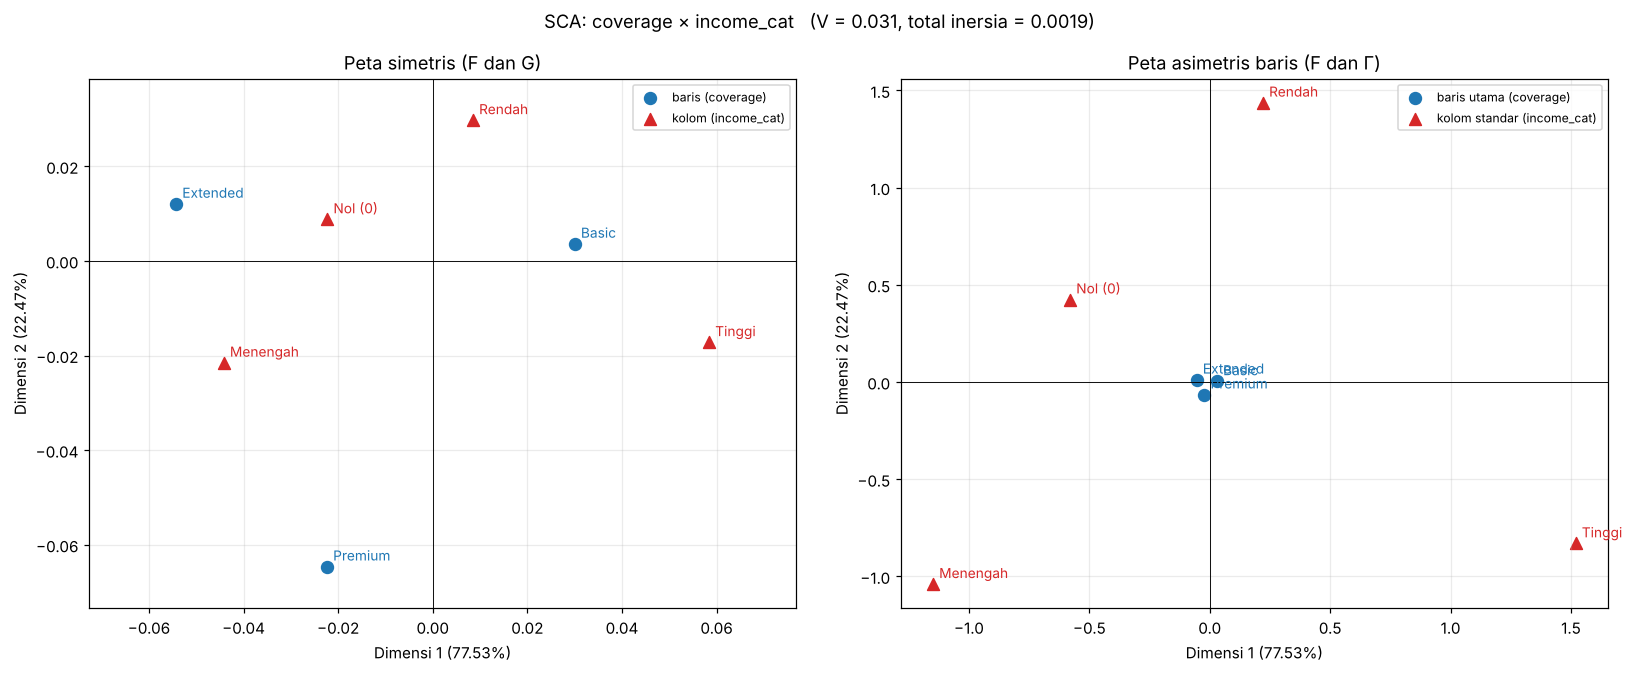

In [52]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 8. `coverage` × `clv_cat` (Kategori CLV)

In [53]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'clv_cat'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

clv_cat,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi),Total
coverage,,,,,
Basic,1548,1772,1255,993,5568
Extended,695,335,810,902,2742
Premium,41,177,217,389,824
Total,2284,2284,2282,2284,9134


I = 3, J = 4, n = 9134
chi2 = 818.6526, db = 6, p-value = 1.436e-173, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.2117


In [54]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.1695,0.1940,0.1374,0.1087
Extended,0.0761,0.0367,0.0887,0.0988
Premium,0.0045,0.0194,0.0238,0.0426


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
c,0.2501,0.2501,0.2498,0.2501


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.2780,0.3182,0.2254,0.1783
Extended,0.2535,0.1222,0.2954,0.3290
Premium,0.0498,0.2148,0.2633,0.4721


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Q1 (Rendah),0.6778,0.3043,0.0180
Q2 (Menengah),0.7758,0.1467,0.0775
Q3 (Tinggi),0.5500,0.3550,0.0951
Q4 (Sangat Tinggi),0.4348,0.3949,0.1703


In [55]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.1524,0.1524,0.1523,0.1524
Extended,0.0751,0.0751,0.0750,0.0751
Premium,0.0226,0.0226,0.0225,0.0226


**P − E (residual mentah)**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.0170,0.0416,-0.0149,-0.0437
Extended,0.0010,-0.0384,0.0137,0.0237
Premium,-0.0181,-0.0032,0.0012,0.0200


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.0437,0.1065,-0.0382,-0.1120
Extended,0.0037,-0.1401,0.0500,0.0865
Premium,-0.1203,-0.0212,0.0081,0.1334


Total inersia = sum(S^2) = 0.089627
Cek chi2/n   = 0.089627  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [56]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 0.072357  0.01727   0.       -0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.268992 0.131416]
Nilai singular (np.svd) : [0.268992 0.131416] | cocok: True
Galat maks |S - UΣVᵀ|   : 5.55e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.2690,0.0724,80.7311,80.7311
Dim 2,0.1314,0.0173,19.2689,100.0000


Jumlah lambda = 0.089627  (total inersia = 0.089627)


In [57]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,-0.7812,-0.1735
Extended,1.0296,1.1274
Premium,1.8529,-2.5791


**Γ  (standar kolom)**

,Dim 1,Dim 2
Q1 (Rendah),-0.6801,1.3633
Q2 (Menengah),-1.1580,-1.2870
Q3 (Tinggi),0.4164,0.4527
Q4 (Sangat Tinggi),1.4221,-0.5286


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,-0.2101,-0.0228
Extended,0.2770,0.1482
Premium,0.4984,-0.3389


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Q1 (Rendah),-0.1829,0.1792
Q2 (Menengah),-0.3115,-0.1691
Q3 (Tinggi),0.1120,0.0595
Q4 (Sangat Tinggi),0.3825,-0.0695


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [58]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,37.2053,1.8356,0.9884,0.0116,0.0272,30.3900
Extended,0.3002,31.8230,38.1573,0.7775,0.2225,0.0296,33.0435
Premium,0.0902,30.9717,60.0071,0.6838,0.3162,0.0328,36.5665


**Kolom (`clv_cat`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Q1 (Rendah),0.2501,11.5648,46.4730,0.5104,0.4896,0.0164,18.2912
Q2 (Menengah),0.2501,33.5341,41.4204,0.7723,0.2277,0.0314,35.0537
Q3 (Tinggi),0.2498,4.3316,5.1206,0.7799,0.2201,0.0040,4.4837
Q4 (Sangat Tinggi),0.2501,50.5695,6.9861,0.9681,0.0319,0.0378,42.1714


Jumlah inersia baris = 0.089627 | kolom = 0.089627 | total = 0.089627


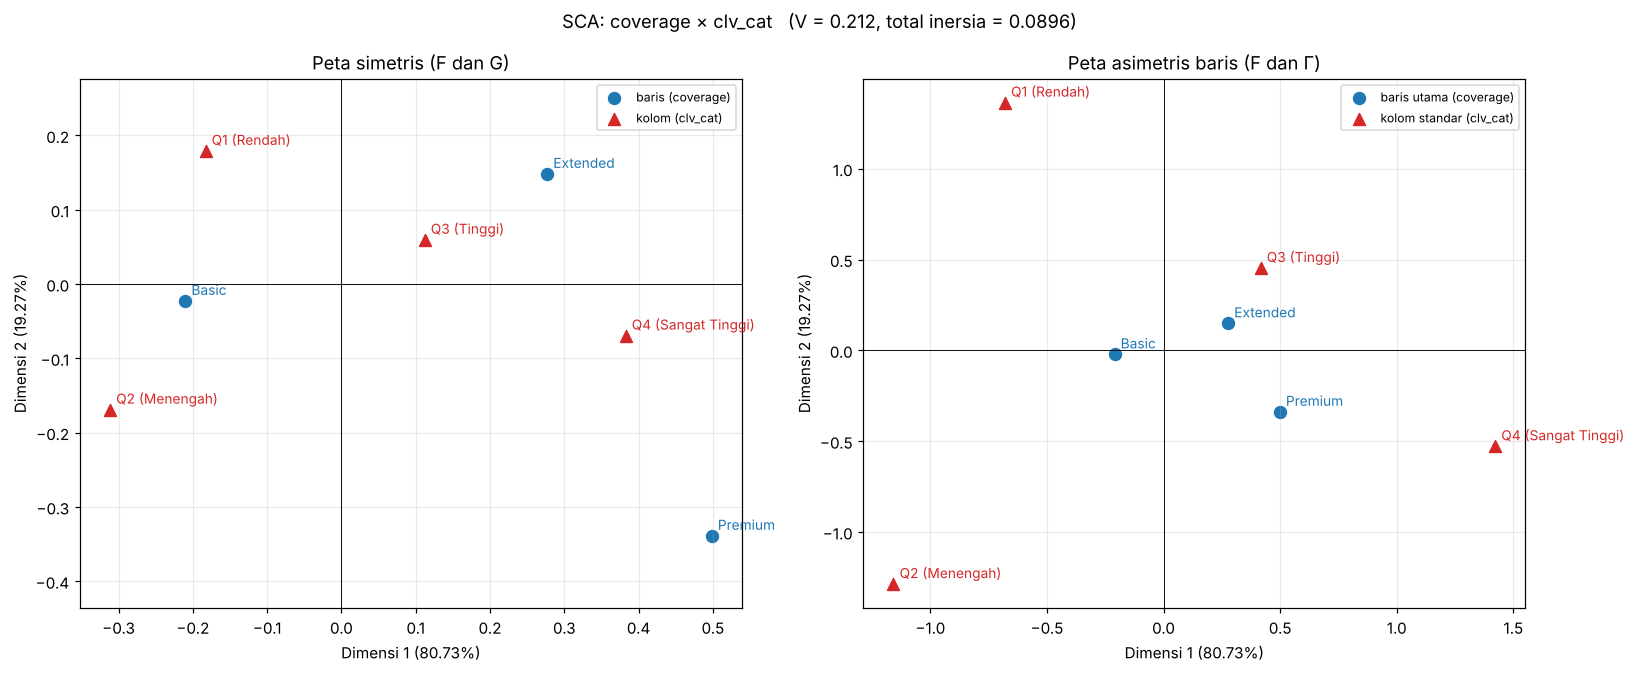

In [59]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 9. `coverage` × `monthly_premium_cat` (Kategori premi bulanan)

In [60]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'monthly_premium_cat'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

monthly_premium_cat,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi),Total
coverage,,,,,
Basic,2298,1675,717,878,5568
Extended,0,660,1295,787,2742
Premium,0,0,257,567,824
Total,2298,2335,2269,2232,9134


I = 3, J = 4, n = 9134
chi2 = 3472.2556, db = 6, p-value = 0.000e+00, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.4360


In [61]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.2516,0.1834,0.0785,0.0961
Extended,0.0000,0.0723,0.1418,0.0862
Premium,0.0000,0.0000,0.0281,0.0621


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
c,0.2516,0.2556,0.2484,0.2444


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.4127,0.3008,0.1288,0.1577
Extended,0.0000,0.2407,0.4723,0.2870
Premium,0.0000,0.0000,0.3119,0.6881


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Q1 (Rendah),1.0000,0.0000,0.0000
Q2 (Menengah),0.7173,0.2827,0.0000
Q3 (Tinggi),0.3160,0.5707,0.1133
Q4 (Sangat Tinggi),0.3934,0.3526,0.2540


In [62]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.1534,0.1558,0.1514,0.1490
Extended,0.0755,0.0767,0.0746,0.0734
Premium,0.0227,0.0231,0.0224,0.0220


**P − E (residual mentah)**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.0982,0.0275,-0.0729,-0.0528
Extended,-0.0755,-0.0045,0.0672,0.0128
Premium,-0.0227,-0.0231,0.0057,0.0400


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Q1 (Rendah),Q2 (Menengah),Q3 (Tinggi),Q4 (Sangat Tinggi)
Basic,0.2508,0.0698,-0.1874,-0.1369
Extended,-0.2748,-0.0162,0.2461,0.0473
Premium,-0.1507,-0.1519,0.0383,0.2696


Total inersia = sum(S^2) = 0.380146
Cek chi2/n   = 0.380146  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [63]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 0.316627  0.063519 -0.       -0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.562696 0.25203 ]
Nilai singular (np.svd) : [0.562696 0.25203 ] | cocok: True
Galat maks |S - UΣVᵀ|   : 1.11e-16
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.5627,0.3166,83.2908,83.2908
Dim 2,0.2520,0.0635,16.7092,100.0000


Jumlah lambda = 0.380146  (total inersia = 0.380146)


In [64]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,0.7923,0.1131
Extended,-1.1131,-1.0451
Premium,-1.6495,2.7137


**Γ  (standar kolom)**

,Dim 1,Dim 2
Q1 (Rendah),1.4080,0.4486
Q2 (Menengah),0.4509,-0.8503
Q3 (Tinggi),-1.0161,-1.0053
Q4 (Sangat Tinggi),-0.8883,1.4496


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,0.4458,0.0285
Extended,-0.6263,-0.2634
Premium,-0.9282,0.6839


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Q1 (Rendah),0.7923,0.1131
Q2 (Menengah),0.2537,-0.2143
Q3 (Tinggi),-0.5718,-0.2534
Q4 (Sangat Tinggi),-0.4999,0.3653


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [65]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,38.2617,0.7793,0.9959,0.0041,0.1216,31.9987
Extended,0.3002,37.1928,32.7875,0.8497,0.1503,0.1386,36.4567
Premium,0.0902,24.5456,66.4332,0.6481,0.3519,0.1199,31.5446


**Kolom (`monthly_premium_cat`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Q1 (Rendah),0.2516,49.8732,5.0633,0.9800,0.0200,0.1611,42.3858
Q2 (Menengah),0.2556,5.1966,18.4813,0.5836,0.4164,0.0282,7.4163
Q3 (Tinggi),0.2484,25.6477,25.1063,0.8359,0.1641,0.0972,25.5572
Q4 (Sangat Tinggi),0.2444,19.2826,51.3491,0.6518,0.3482,0.0937,24.6406


Jumlah inersia baris = 0.380146 | kolom = 0.380146 | total = 0.380146


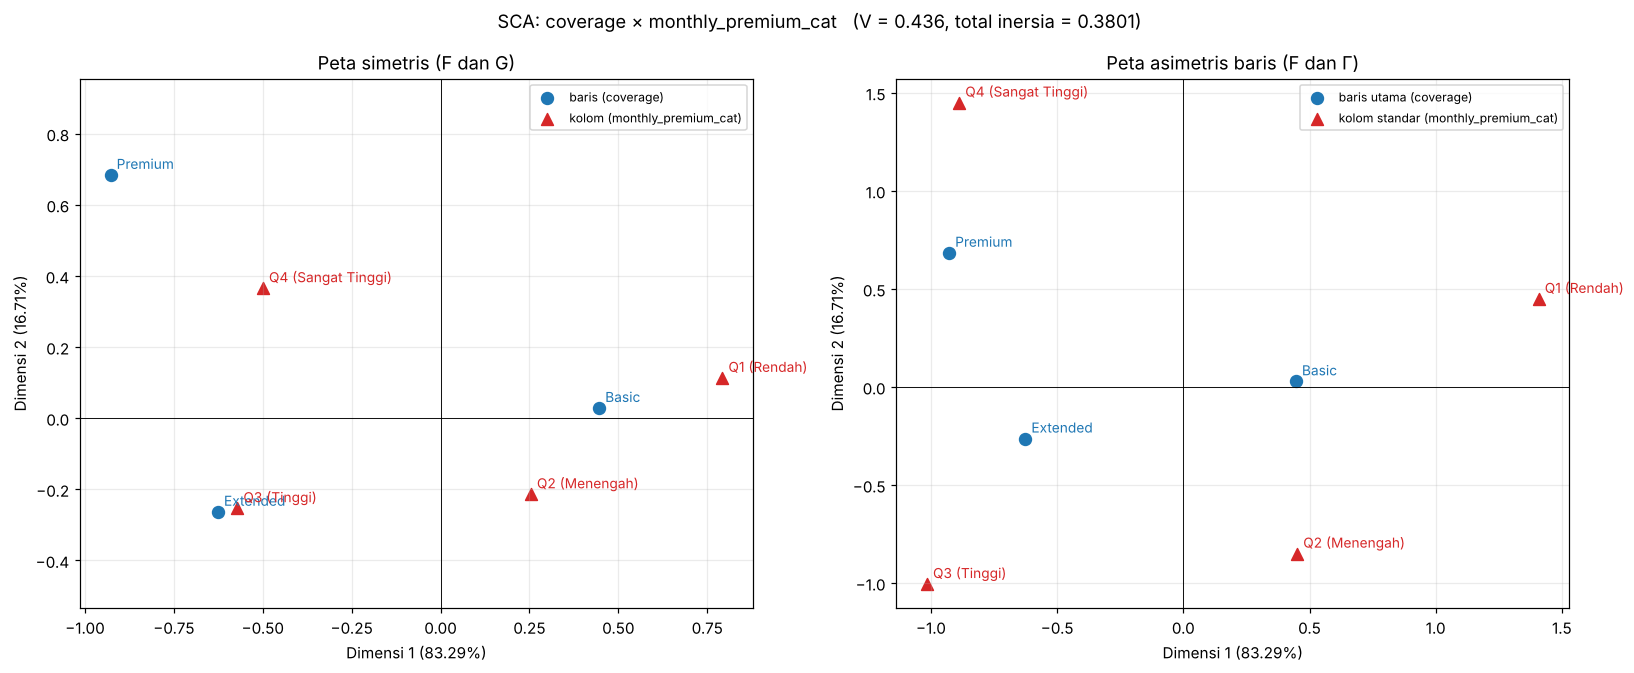

In [66]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 10. `coverage` × `total_claim_cat` (Kategori total klaim)

In [67]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'total_claim_cat'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

total_claim_cat,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar),Total
coverage,,,,,
Basic,1560,1914,1227,867,5568
Extended,593,334,834,981,2742
Premium,131,35,222,436,824
Total,2284,2283,2283,2284,9134


I = 3, J = 4, n = 9134
chi2 = 1213.1357, db = 6, p-value = 6.872e-259, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.2577


In [68]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar)
Basic,0.1708,0.2095,0.1343,0.0949
Extended,0.0649,0.0366,0.0913,0.1074
Premium,0.0143,0.0038,0.0243,0.0477


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar)
c,0.2501,0.2499,0.2499,0.2501


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar)
Basic,0.2802,0.3438,0.2204,0.1557
Extended,0.2163,0.1218,0.3042,0.3578
Premium,0.1590,0.0425,0.2694,0.5291


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Q1 (Kecil),0.6830,0.2596,0.0574
Q2 (Sedang),0.8384,0.1463,0.0153
Q3 (Besar),0.5375,0.3653,0.0972
Q4 (Sangat Besar),0.3796,0.4295,0.1909


In [69]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar)
Basic,0.1524,0.1524,0.1524,0.1524
Extended,0.0751,0.0750,0.0750,0.0751
Premium,0.0226,0.0225,0.0225,0.0226


**P − E (residual mentah)**

,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar)
Basic,0.0184,0.0572,-0.0180,-0.0575
Extended,-0.0101,-0.0385,0.0163,0.0323
Premium,-0.0082,-0.0187,0.0018,0.0252


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Q1 (Kecil),Q2 (Sedang),Q3 (Besar),Q4 (Sangat Besar)
Basic,0.0470,0.1465,-0.0462,-0.1473
Extended,-0.0370,-0.1404,0.0594,0.1180
Premium,-0.0547,-0.1246,0.0117,0.1676


Total inersia = sum(S^2) = 0.132815
Cek chi2/n   = 0.132815  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [70]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [ 0.13027   0.002546  0.       -0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.360929 0.050453]
Nilai singular (np.svd) : [0.360929 0.050453] | cocok: True
Galat maks |S - UΣVᵀ|   : 1.11e-16
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.3609,0.1303,98.0834,98.0834
Dim 2,0.0505,0.0025,1.9166,100.0000


Jumlah lambda = 0.132815  (total inersia = 0.132815)


In [71]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,-0.7729,-0.2076
Extended,0.9793,1.1714
Premium,1.9640,-2.4955


**Γ  (standar kolom)**

,Dim 1,Dim 2
Q1 (Kecil),-0.4461,0.3813
Q2 (Sedang),-1.3149,-0.8106
Q3 (Besar),0.3694,1.4609
Q4 (Sangat Besar),1.3912,-1.0313


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,-0.2790,-0.0105
Extended,0.3534,0.0591
Premium,0.7089,-0.1259


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Q1 (Kecil),-0.1610,0.0192
Q2 (Sedang),-0.4746,-0.0409
Q3 (Besar),0.1333,0.0737
Q4 (Sangat Besar),0.5021,-0.0520


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [72]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,36.4146,2.6263,0.9986,0.0014,0.0475,35.7670
Extended,0.3002,28.7868,41.1934,0.9728,0.0272,0.0385,29.0246
Premium,0.0902,34.7985,56.1802,0.9694,0.0306,0.0468,35.2083


**Kolom (`total_claim_cat`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Q1 (Kecil),0.2501,4.9757,3.6351,0.9859,0.0141,0.0066,4.9500
Q2 (Sedang),0.2499,43.2166,16.4238,0.9926,0.0074,0.0567,42.7031
Q3 (Besar),0.2499,3.4103,53.3458,0.7659,0.2341,0.0058,4.3674
Q4 (Sangat Besar),0.2501,48.3974,26.5953,0.9894,0.0106,0.0637,47.9795


Jumlah inersia baris = 0.132815 | kolom = 0.132815 | total = 0.132815


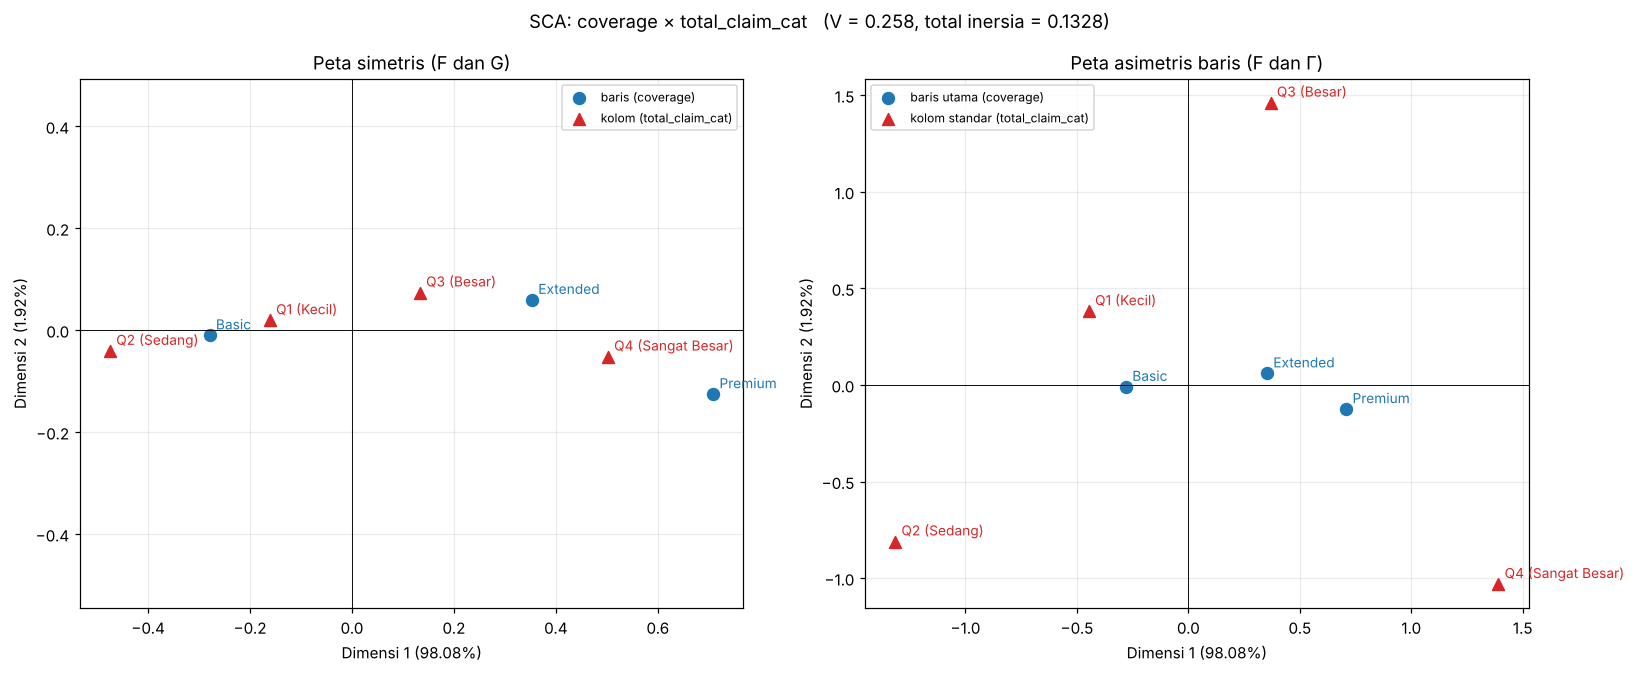

In [73]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## 11. `coverage` × `tenure_cat` (Kategori masa kepesertaan)

In [74]:
# Langkah 1: tabel kontingensi, uji χ², Cramér's V
COL = 'tenure_cat'
st = langkah1_kontingensi(COL)

**Tabel kontingensi N (dengan total)**

tenure_cat,Baru,Menengah,Lama,Sangat Lama,Total
coverage,,,,,
Basic,1405,1433,1367,1363,5568
Extended,700,665,711,666,2742
Premium,202,227,158,237,824
Total,2307,2325,2236,2266,9134


I = 3, J = 4, n = 9134
chi2 = 20.9853, db = 6, p-value = 1.846e-03, nilai kritis(0.05) = 12.5916
Keputusan: H0 ditolak -> ada hubungan signifikan
Cramer's V = 0.0339


In [75]:
# Langkah 2: matriks korespondensi, massa, profil baris/kolom
langkah2_profil(st)

**P = N/n**

,Baru,Menengah,Lama,Sangat Lama
Basic,0.1538,0.1569,0.1497,0.1492
Extended,0.0766,0.0728,0.0778,0.0729
Premium,0.0221,0.0249,0.0173,0.0259


**Massa baris r dan massa kolom c**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


,Baru,Menengah,Lama,Sangat Lama
c,0.2526,0.2545,0.2448,0.2481


**Profil baris R = Dr⁻¹P** (tiap baris berjumlah 1)

,Baru,Menengah,Lama,Sangat Lama
Basic,0.2523,0.2574,0.2455,0.2448
Extended,0.2553,0.2425,0.2593,0.2429
Premium,0.2451,0.2755,0.1917,0.2876


**Profil kolom C = Dc⁻¹Pᵀ** (tiap baris berjumlah 1)

,Basic,Extended,Premium
Baru,0.6090,0.3034,0.0876
Menengah,0.6163,0.2860,0.0976
Lama,0.6114,0.3180,0.0707
Sangat Lama,0.6015,0.2939,0.1046


In [76]:
# Langkah 3: ekspektasi, residual, matriks terstandarisasi S
langkah3_residual(st)

**E = r cᵀ (ekspektasi di bawah independensi)**

,Baru,Menengah,Lama,Sangat Lama
Basic,0.1540,0.1552,0.1492,0.1512
Extended,0.0758,0.0764,0.0735,0.0745
Premium,0.0228,0.0230,0.0221,0.0224


**P − E (residual mentah)**

,Baru,Menengah,Lama,Sangat Lama
Basic,-0.0001,0.0017,0.0004,-0.0020
Extended,0.0008,-0.0036,0.0044,-0.0016
Premium,-0.0007,0.0019,-0.0048,0.0036


**S = Dr^(-1/2)(P − rcᵀ)Dc^(-1/2) (residual terstandarisasi)**

,Baru,Menengah,Lama,Sangat Lama
Basic,-0.0004,0.0044,0.0011,-0.0052
Extended,0.0030,-0.0131,0.0161,-0.0057
Premium,-0.0044,0.0125,-0.0322,0.0238


Total inersia = sum(S^2) = 0.002297
Cek chi2/n   = 0.002297  (harus sama)
Cek baris/kolom P−E berjumlah 0: True / True


In [77]:
# Langkah 4: SVD dan inersia per dimensi
langkah4_svd(st)

K = min(I-1, J-1) = 2
Semua eigenvalue SᵀS (urut menurun): [0.002186 0.000112 0.       0.      ]  -> sisanya (≈0) dimensi trivial
Nilai singular (eigen)  : [0.046754 0.010562]
Nilai singular (np.svd) : [0.046754 0.010562] | cocok: True
Galat maks |S - UΣVᵀ|   : 2.90e-17
UᵀU = I: True | VᵀV = I: True


,sigma_k,lambda_k,% inersia,% kumulatif
Dim 1,0.0468,0.0022,95.1448,95.1448
Dim 2,0.0106,0.0001,4.8552,100.0000


Jumlah lambda = 0.002297  (total inersia = 0.002297)


In [78]:
# Langkah 5: koordinat standar dan utama
langkah5_koordinat(st)

**Φ  (standar baris)**

,Dim 1,Dim 2
Basic,0.0528,0.7985
Extended,0.7930,-1.3047
Premium,-2.9956,-1.0542


**Γ  (standar kolom)**

,Dim 1,Dim 2
Baru,0.2241,-0.1773
Menengah,-0.7083,1.5210
Lama,1.5562,-0.1114
Sangat Lama,-1.0369,-1.2701


**F = ΦΣ  (utama baris)**

,Dim 1,Dim 2
Basic,0.0025,0.0084
Extended,0.0371,-0.0138
Premium,-0.1401,-0.0111


**G = ΓΣ  (utama kolom)**

,Dim 1,Dim 2
Baru,0.0105,-0.0019
Menengah,-0.0331,0.0161
Lama,0.0728,-0.0012
Sangat Lama,-0.0485,-0.0134


Cek ΦᵀDrΦ = I : True | ΓᵀDcΓ = I : True
Cek rumus transisi F = RΓ : True | G = CΦ : True


In [79]:
# Langkah 6: kontribusi, cos², inersia titik
langkah6_kontribusi(st)

**Baris (`coverage`)** | rata-rata kontribusi 1/I = 33.3%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Basic,0.6096,0.1700,38.8710,0.0789,0.9211,0.0000,2.0490
Extended,0.3002,18.8772,51.1031,0.8786,0.1214,0.0005,20.4419
Premium,0.0902,80.9528,10.0259,0.9937,0.0063,0.0018,77.5092


**Kolom (`tenure_cat`)** | rata-rata kontribusi 1/J = 25.0%

,massa,ctr D1 (%),ctr D2 (%),cos2 D1,cos2 D2,inersia,inersia (% total)
Baru,0.2526,1.2680,0.7942,0.9690,0.0310,0.0000,1.2450
Menengah,0.2545,12.7716,58.8841,0.8095,0.1905,0.0003,15.0105
Lama,0.2448,59.2855,0.3040,0.9997,0.0003,0.0013,56.4218
Sangat Lama,0.2481,26.6749,40.0177,0.9289,0.0711,0.0006,27.3227


Jumlah inersia baris = 0.002297 | kolom = 0.002297 | total = 0.002297


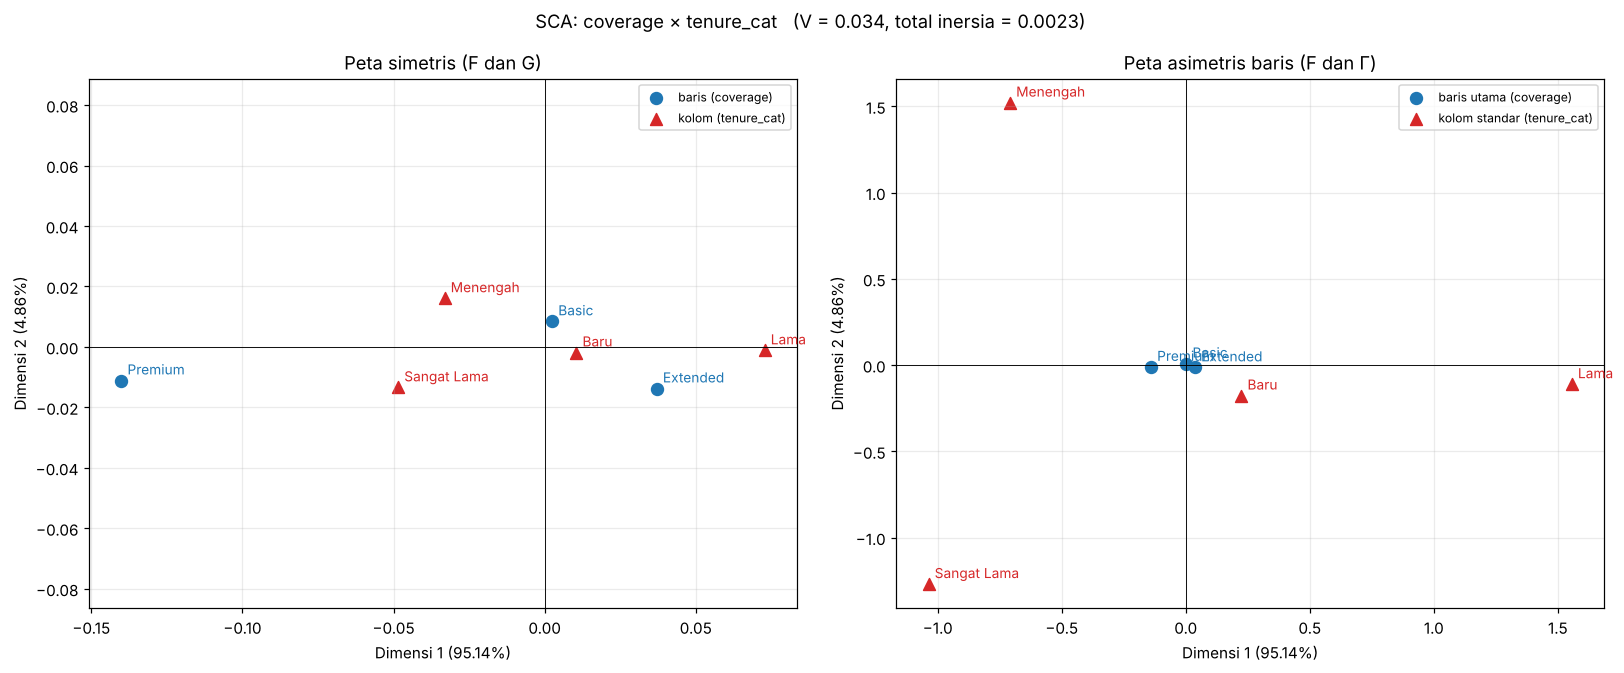

In [80]:
# Langkah 7: peta simetris dan asimetris
langkah7_peta(st)

---
## Ringkasan 11 pasangan SCA

In [81]:
ringkas = pd.DataFrame(RESULTS).T
ringkas['p_value'] = ringkas['p_value'].map(lambda x: f'{x:.2e}')
for c in ['I','J','db']: ringkas[c] = ringkas[c].astype(int)
display(ringkas.sort_values('cramers_V', ascending=False))

,I,J,chi2,db,p_value,cramers_V,total_inersia,pct_dim1,pct_dim2
monthly_premium_cat,3,4,3472.2556,6,0.00e+00,0.4360,0.3801,83.2908,16.7092
total_claim_cat,3,4,1213.1357,6,6.87e-259,0.2577,0.1328,98.0834,1.9166
clv_cat,3,4,818.6526,6,1.44e-173,0.2117,0.0896,80.7311,19.2689
renew_offer_type,3,4,43.6737,6,8.58e-08,0.0489,0.0048,99.5819,0.4181
region,3,3,31.2698,4,2.70e-06,0.0414,0.0034,99.8082,0.1918
employment_status,3,5,21.7666,8,5.37e-03,0.0345,0.0024,86.0304,13.9696
tenure_cat,3,4,20.9853,6,1.85e-03,0.0339,0.0023,95.1448,4.8552
education,3,5,18.6511,8,1.68e-02,0.0320,0.0020,69.6809,30.3191
vehicle_class,3,6,18.3085,10,5.00e-02,0.0317,0.0020,95.5286,4.4714
income_cat,3,4,17.4127,6,7.88e-03,0.0309,0.0019,77.5273,22.4727


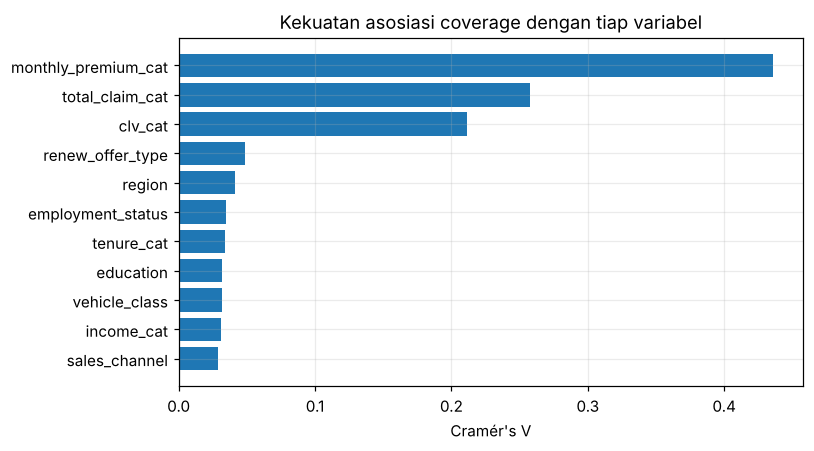

In [82]:
ringkas_num = pd.DataFrame(RESULTS).T.sort_values('cramers_V')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(ringkas_num.index, ringkas_num['cramers_V'], color='tab:blue')
ax.set_xlabel("Cramér's V"); ax.set_title('Kekuatan asosiasi coverage dengan tiap variabel')
plt.tight_layout(); plt.show()